# Étude G5 — Indices météo détaillés (Copernicus, Seine-et-Marne)

**Question G5 (`docs/sources/matrice.md`) :** quelles conditions météorologiques, mesurées par les indices de danger (*Fire Weather Index* `FWI`, *Drought Code* `DC`, *Duff Moisture Code* `DMC`, *Fine Fuel Moisture Code* `FFMC`), ont été associées aux départs de feu et aux incendies les plus importants dans le 77 ?

**Objectif (`kpi/objectifs.md`) :** trouver, avant le `11 décembre 2026`, au moins un indice détaillé Copernicus qui sépare mieux les jours avec feu des jours sans feu dans le 77 que le niveau `1–4` de la *Météo des forêts* sur `2024` et `2025`, à nombre de jours d'alerte égal (`K = 22` jours).

Règles communes reprises de l'équipe :
- **Un départ de feu = une fiche BDIFF** (`décision 006`).
- **Météo des forêts :** on utilise `niveau_j1`, rattaché à `date_publication + 1 jour` (même convention déduite que `01_etude_g2_seuil.ipynb`).
- **Périmètre :** Seine-et-Marne (`77`) entier, sans découpage par secteur (`décision 003`).
- **Lecture stricte :** toutes les données lues ici proviennent de `../data/bronze/` (aucun chemin local personnel).

## 1. Chargement des données (`../data/bronze/`)

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BRONZE = Path('..') / 'data' / 'bronze'

# Correspondance entre noms métier (G5) et colonnes Copernicus (GRIB / CSV)
INDICES_G5 = {
    'ffmcode': 'FFMC (combustibles fins)',
    'dufmcode': 'DMC (humus / litière moyenne)',
    'fwinx': 'FWI (indice global)',
    'drtcode': 'DC (sécheresse profonde)',
}

### Copernicus (points du 77 et agrégats départementaux)

In [2]:
cop_morceaux = []
dept_morceaux = []

for annee in [2024, 2025, 2026]:
    df_77 = pd.read_csv(BRONZE / 'copernicus' / f'copernicus_{annee}_77.csv')
    df_77['annee'] = annee
    cop_morceaux.append(df_77)

    df_dept = pd.read_csv(BRONZE / 'copernicus' / f'copernicus_{annee}_idf_dept_jour.csv', dtype={'code_departement': str})
    df_dept['annee'] = annee
    dept_morceaux.append(df_dept)

    print(
        f"Copernicus {annee} (77) : {df_77.shape} | {df_77['time'].min()} -> {df_77['time'].max()} "
        f"| colonnes absentes vs 2024 : {set(cop_morceaux[0].columns) - set(df_77.columns) or 'aucune'}"
    )

cop_77 = pd.concat(cop_morceaux, ignore_index=True)
cop_77['date_concernee'] = pd.to_datetime(cop_77['time']).dt.date

cop_dept = pd.concat(dept_morceaux, ignore_index=True)
cop_dept['code_departement'] = cop_dept['code_departement'].str.strip().str.zfill(2)
cop_dept['date_concernee'] = pd.to_datetime(cop_dept['time']).dt.date

cop_77[['time', 'values', 'commune_77', 'latitude', 'longitude', 'ffmcode', 'dufmcode', 'fwinx', 'drtcode']].head(6)

Copernicus 2024 (77) : (2196, 18) | 2024-01-01 -> 2024-12-31 | colonnes absentes vs 2024 : aucune
Copernicus 2025 (77) : (2190, 18) | 2025-01-01 -> 2025-12-31 | colonnes absentes vs 2024 : aucune
Copernicus 2026 (77) : (1458, 16) | 2026-01-01 -> 2026-08-31 | colonnes absentes vs 2024 : {'buinfdr', 'fdimrk'}


,time,values,commune_77,latitude,longitude,ffmcode,dufmcode,fwinx,drtcode
0,2024-01-01,3,Étrépilly,49.039793,2.916667,73.216800,1.00,0.718750,15.00
1,2024-01-01,8,Neufmoutiers-en-Brie,48.758762,2.800000,73.792970,1.25,0.804688,17.75
2,2024-01-01,9,Choisy-en-Brie,48.758762,3.200000,70.421875,0.50,0.617188,15.00
3,2024-01-01,14,Féricy,48.477732,2.800000,74.431640,1.75,0.875000,24.50
4,2024-01-01,15,Paroy,48.477732,3.200000,74.212890,1.75,0.941406,21.50
5,2024-01-01,20,Chaintreaux,48.196702,2.800000,74.919920,2.25,1.417969,54.50


### BDIFF (`2024–2025`) et Météo des forêts (référence G2)

In [3]:
# BDIFF : séparateur ';', 2 lignes d'en-tête descriptives avant les colonnes
bdiff = pd.read_csv(BRONZE / 'bdiff' / 'incendies_idf_2024_2025.csv', sep=';', skiprows=2, dtype=str)
bdiff['date_alerte'] = pd.to_datetime(bdiff['Date de première alerte'])
bdiff['date_concernee'] = bdiff['date_alerte'].dt.date
bdiff['surface_m2'] = pd.to_numeric(bdiff['Surface parcourue (m2)'], errors='raise')
bdiff['Annee_int'] = bdiff['Année'].astype(int)

b77 = bdiff[bdiff['Département'] == '77'].copy()
print(f"BDIFF Île-de-France : {len(bdiff)} feux | Seine-et-Marne (77) : {len(b77)} feux, {b77['date_concernee'].nunique()} jours avec feu, {int(b77['surface_m2'].sum())} m2")

# Météo des forêts : même lecture que 01_etude_g2_seuil.ipynb
fichiers_mdf = {2024: ',', 2025: ',', 2026: ';'}
mdf_morceaux = []
for annee, sep in fichiers_mdf.items():
    df = pd.read_csv(BRONZE / 'meteo_des_forets' / f'mdf_{annee}.csv', sep=sep, dtype=str)
    df = df.rename(columns={'dep_nom': 'nom_dep'})
    df['annee_fichier'] = annee
    mdf_morceaux.append(df)

mdf = pd.concat(mdf_morceaux, ignore_index=True)
mdf['date_publication'] = pd.to_datetime(mdf['date'], utc=True).dt.tz_convert('Europe/Paris')
mdf['code_departement'] = mdf['num_dep'].str.strip().str.zfill(2)
mdf['niveau_j1'] = mdf['niveau_j1'].astype(int)
mdf['date_concernee'] = (mdf['date_publication'].dt.normalize() + pd.Timedelta(days=1)).dt.date

mdf77 = mdf[mdf['code_departement'] == '77'].copy()
mdf77.groupby('annee_fichier')['date_concernee'].agg(['min', 'max', 'nunique'])

BDIFF Île-de-France : 71 feux | Seine-et-Marne (77) : 65 feux, 56 jours avec feu, 39957 m2


,min,max,nunique
annee_fichier,,,
2024,2024-06-04,2024-10-01,120
2025,2025-06-04,2025-10-01,120
2026,2026-05-29,2026-10-06,131


## 2. Contrôles qualité avant de croiser

Avant de calculer les indicateurs, on vérifie quatre points :
1. Aucune valeur manquante ni aucun doublon sur les 4 indices Copernicus (`2024–2026`) et dans la BDIFF (`77`).
2. Liste exacte des `6` points de la grille N320 situés dans les communes du `77`.
3. Cohérence entre `copernicus_*_77.csv` (grille détaillée) et `copernicus_*_idf_dept_jour.csv` (moyenne départementale précalculée).
4. Concentration géographique des feux dans le `77`.

In [4]:
cols_indices = list(INDICES_G5.keys())
print("Valeurs manquantes Copernicus 77 (4 indices G5) :", cop_77[cols_indices].isna().sum().to_dict())
print("Doublons (time, values) Copernicus 77 :", int(cop_77.duplicated(['date_concernee', 'values']).sum()))
print("Valeurs manquantes BDIFF 77 (date, commune, surface) :", b77[['Date de première alerte', 'Code INSEE', 'surface_m2']].isna().sum().to_dict())
print("Doublons (Année, Numéro) BDIFF 77 :", int(b77.duplicated(['Année', 'Numéro']).sum()))

# Les 6 points retenus à l'intérieur du 77
points_77 = (
    cop_77[['values', 'commune_77', 'latitude', 'longitude']]
    .drop_duplicates()
    .sort_values('values')
    .reset_index(drop=True)
)
display(points_77)

# Vérification de cohérence : cop_*_idf_dept_jour.csv correspond-il à la moyenne des 6 points ?
moy_calc = cop_77.groupby('date_concernee')[cols_indices].mean().reset_index()
moy_dep = cop_dept[cop_dept['code_departement'] == '77'][['date_concernee'] + cols_indices]
comp_moy = moy_calc.merge(moy_dep, on='date_concernee', suffixes=('_calc', '_dept'))
ecarts_max = {c: float((comp_moy[f'{c}_calc'] - comp_moy[f'{c}_dept']).abs().max()) for c in cols_indices}
print("Écart max entre moyenne des 6 points et copernicus_*_idf_dept_jour :", ecarts_max)

Valeurs manquantes Copernicus 77 (4 indices G5) : {'ffmcode': 0, 'dufmcode': 0, 'fwinx': 0, 'drtcode': 0}
Doublons (time, values) Copernicus 77 : 0
Valeurs manquantes BDIFF 77 (date, commune, surface) : {'Date de première alerte': 0, 'Code INSEE': 0, 'surface_m2': 0}
Doublons (Année, Numéro) BDIFF 77 : 0


,values,commune_77,latitude,longitude
0,3,Étrépilly,49.039793,2.916667
1,8,Neufmoutiers-en-Brie,48.758762,2.800000
2,9,Choisy-en-Brie,48.758762,3.200000
3,14,Féricy,48.477732,2.800000
4,15,Paroy,48.477732,3.200000
5,20,Chaintreaux,48.196702,2.800000


Écart max entre moyenne des 6 points et copernicus_*_idf_dept_jour : {'ffmcode': 1.4210854715202004e-14, 'dufmcode': 1.4210854715202004e-14, 'fwinx': 7.105427357601002e-15, 'drtcode': 2.842170943040401e-14}


In [5]:
# Répartition des 65 feux du 77 (2024-2025) par commune
top_communes = (
    b77.groupby('Nom de la commune')
    .agg(feux=('Numéro', 'count'), surface_m2=('surface_m2', 'sum'))
    .sort_values(['feux', 'surface_m2'], ascending=False)
)
top_communes['part_feux_%'] = (100 * top_communes['feux'] / len(b77)).round(1)
top_communes.head(8)

,feux,surface_m2,part_feux_%
Nom de la commune,,,
Fontainebleau,29,33945,44.6
Le Vaudoué,3,2205,4.6
Nemours,3,810,4.6
Arbonne-la-Forêt,2,2004,3.1
Villiers-sous-Grez,2,102,3.1
Brou-sur-Chantereine,2,21,3.1
Verneuil-l'Étang,2,6,3.1
Montereau-Fault-Yonne,2,2,3.1


## 3. Choix d'agrégation des 6 points du 77 : `max` vs moyenne (`mean`)

Près de la moitié des feux du département (`29 / 65`, soit `44,6 %`) ont lieu à **Fontainebleau**, dans le sud du 77. Or les 6 points météo couvrent tout le département du nord (`Étrépilly`) au sud (`Chaintreaux`).

On teste si la **moyenne départementale** (celle de `copernicus_*_idf_dept_jour.csv`) lisse et masque un pic local au sud, ou s'il vaut mieux prendre le **`max` quotidien** des 6 points.

In [6]:
# Gradient nord -> sud des 6 points en 2024-2025
cop_2425 = cop_77[cop_77['annee'].isin([2024, 2025])].copy()
profil_pts = (
    cop_2425.groupby(['values', 'commune_77', 'latitude'])
    .agg(fwinx_moy=('fwinx', 'mean'), fwinx_max=('fwinx', 'max'), ffmcode_moy=('ffmcode', 'mean'))
    .round(2)
    .reset_index()
    .sort_values('latitude', ascending=False)
)
display(profil_pts)

# Cas réel : le plus gros incendie de 2024-2025 (16/05/2025 à Fontainebleau, 30 000 m²)
pic_16mai = cop_2425[cop_2425['time'] == '2025-05-16'][['values', 'commune_77', 'fwinx', 'ffmcode', 'dufmcode', 'drtcode']].sort_values('fwinx', ascending=False)
print("Valeurs des 6 points le 2025-05-16 (feu de 30 000 m2 à Fontainebleau) :")
display(pic_16mai.round(2))
print(f"FWI le 2025-05-16 -> max = {pic_16mai['fwinx'].max():.2f} (Féricy) | mean = {pic_16mai['fwinx'].mean():.2f} (seuil EFFIS élevé = 21.3)")

,values,commune_77,latitude,fwinx_moy,fwinx_max,ffmcode_moy
0,3,Étrépilly,49.039793,3.95,35.74,67.74
1,8,Neufmoutiers-en-Brie,48.758762,3.86,33.52,67.88
2,9,Choisy-en-Brie,48.758762,3.99,30.68,68.23
3,14,Féricy,48.477732,4.27,37.61,68.79
4,15,Paroy,48.477732,4.35,39.61,69.55
5,20,Chaintreaux,48.196702,4.65,43.93,69.37


Valeurs des 6 points le 2025-05-16 (feu de 30 000 m2 à Fontainebleau) :


,values,commune_77,fwinx,ffmcode,dufmcode,drtcode
3009,14,Féricy,22.20,88.78,57.75,190.00
3006,3,Étrépilly,20.95,88.67,41.50,196.75
3010,15,Paroy,20.30,88.54,43.25,185.00
3008,9,Choisy-en-Brie,20.25,88.25,41.00,186.25
3011,20,Chaintreaux,20.05,88.29,46.50,170.00
3007,8,Neufmoutiers-en-Brie,19.97,88.29,43.25,181.00


FWI le 2025-05-16 -> max = 22.20 (Féricy) | mean = 20.62 (seuil EFFIS élevé = 21.3)


In [7]:
# Table quotidienne 2024-2025 (731 jours) : agrégation max et mean + feux BDIFF
aggs = {}
for c in cols_indices:
    aggs[f'{c}_max'] = (c, 'max')
    aggs[f'{c}_mean'] = (c, 'mean')

cop_jour = cop_2425.groupby('date_concernee').agg(**aggs).reset_index()
feux_jour = (
    b77.groupby('date_concernee')
    .agg(nb_feux=('Numéro', 'count'), surface_m2=('surface_m2', 'sum'))
    .reset_index()
)

table_731 = cop_jour.merge(feux_jour, on='date_concernee', how='left').fillna({'nb_feux': 0, 'surface_m2': 0.0})
table_731['nb_feux'] = table_731['nb_feux'].astype(int)
table_731['jour_avec_feu'] = table_731['nb_feux'] > 0
table_731['annee'] = pd.to_datetime(table_731['date_concernee']).dt.year

# Impact concret du max vs mean aux seuils standards EFFIS du FWI sur les 731 jours
lignes_effis = []
surf_tot = float(table_731['surface_m2'].sum())
for seuil in [5.2, 11.2, 21.3, 38.0]:
    for agg in ['max', 'mean']:
        col = f'fwinx_{agg}'
        alerte = table_731[table_731[col] >= seuil]
        n_j = len(alerte)
        tp_j = int(alerte['jour_avec_feu'].sum())
        surf_ok = float(alerte['surface_m2'].sum())
        lignes_effis.append({
            'seuil_FWI': seuil,
            'regle': agg,
            'jours_alerte': n_j,
            'jours_avec_feu': tp_j,
            'precision_%': round(100 * tp_j / n_j, 2) if n_j else 0.0,
            'surface_captee_%': round(100 * surf_ok / surf_tot, 2),
            'surface_manquee_m2': int(surf_tot - surf_ok),
        })

pd.DataFrame(lignes_effis)

,seuil_FWI,regle,jours_alerte,jours_avec_feu,precision_%,surface_captee_%,surface_manquee_m2
0,5.2,max,239,44,18.41,94.91,2032
1,5.2,mean,199,41,20.60,94.40,2237
2,11.2,max,127,31,24.41,92.28,3085
3,11.2,mean,97,26,26.80,86.50,5395
4,21.3,max,39,13,33.33,83.18,6719
5,21.3,mean,22,6,27.27,7.08,37128
6,38.0,max,2,1,50.00,0.50,39756
7,38.0,mean,0,0,0.00,0.00,39957


**Décision méthodologique retenue :** au seuil élevé `FWI >= 21,3`, le `max` capte **`83,2 %`** de la surface brûlée (`13 / 39 = 33,3 %` de précision), alors que la `mean` retombe à `20,62` le `16/05/2025` et ne capte plus que **`7,1 %`** de la surface (`6 / 22 = 27,3 %`). On retient donc le **`max` quotidien** en règle principale, et on garde la `mean` en variante de sensibilité.

## 4. Comparaison à budget d'alerte égal sur la fenêtre Météo des forêts (`240` j)

Pour comparer à armes égales avec la fiche G2 (`01_etude_g2_seuil.ipynb`), on se place exactement sur les **`240` jours publiés par la Météo des forêts** en `2024` et `2025` (`04/06–01/10`), et on calibre chaque indice Copernicus pour avoir **exactement `K = 22` jours d'alerte** (le volume observé de `niveau_j1 >= 2`).

In [8]:
mdf_2425 = mdf77[mdf77['annee_fichier'].isin([2024, 2025])][['date_concernee', 'niveau_j1']].copy()
table_mdf = mdf_2425.merge(table_731, on='date_concernee', how='left')

print(
    f"Fenêtre exacte Météo des forêts : {len(table_mdf)} jours | "
    f"{int(table_mdf['jour_avec_feu'].sum())} jours avec feu | "
    f"{int(table_mdf['nb_feux'].sum())} feux | {int(table_mdf['surface_m2'].sum())} m2"
)

def evaluer_topk(df, col, k=22, ref_prec=None):
    s = df.sort_values(col, ascending=False).reset_index(drop=True)
    seuil = float(s.loc[k - 1, col])
    alerte = s[s[col] >= seuil]
    hors = s[s[col] < seuil]
    n_j = len(alerte)
    tp_j = int(alerte['jour_avec_feu'].sum())
    prec = 100.0 * tp_j / n_j
    surf_tot_df = float(df['surface_m2'].sum())
    surf_ok = float(alerte['surface_m2'].sum())
    res = {
        'indicateur': col,
        'seuil_S': round(seuil, 2),
        'jours_alerte': n_j,
        'jours_avec_feu': tp_j,
        'precision_%': round(prec, 1),
        'ecart_pts_vs_MdF': round(prec - ref_prec, 1) if ref_prec is not None else 0.0,
        'feux_captes': f"{int(alerte['nb_feux'].sum())}/{int(df['nb_feux'].sum())}",
        'surface_captee_%': round(100.0 * surf_ok / surf_tot_df, 1),
        'surface_hors_alerte_%': round(100.0 * float(hors['surface_m2'].sum()) / surf_tot_df, 1),
    }
    return res

# Référence Météo des forêts (niveau_j1 >= 2)
alerte_mdf = table_mdf[table_mdf['niveau_j1'] >= 2]
prec_mdf = 100.0 * float(alerte_mdf['jour_avec_feu'].mean())
surf_mdf_tot = float(table_mdf['surface_m2'].sum())
surf_mdf_ok = float(alerte_mdf['surface_m2'].sum())

lignes_comp = [{
    'indicateur': 'Météo des forêts (niveau >= 2)',
    'seuil_S': 2.0,
    'jours_alerte': len(alerte_mdf),
    'jours_avec_feu': int(alerte_mdf['jour_avec_feu'].sum()),
    'precision_%': round(prec_mdf, 1),
    'ecart_pts_vs_MdF': 0.0,
    'feux_captes': f"{int(alerte_mdf['nb_feux'].sum())}/{int(table_mdf['nb_feux'].sum())}",
    'surface_captee_%': round(100.0 * surf_mdf_ok / surf_mdf_tot, 1),
    'surface_hors_alerte_%': round(100.0 * (surf_mdf_tot - surf_mdf_ok) / surf_mdf_tot, 1),
}]

for col in ['ffmcode_max', 'ffmcode_mean', 'dufmcode_max', 'dufmcode_mean', 'fwinx_max', 'fwinx_mean', 'drtcode_max', 'drtcode_mean']:
    lignes_comp.append(evaluer_topk(table_mdf, col, k=22, ref_prec=prec_mdf))

df_comp_mdf = pd.DataFrame(lignes_comp)
df_comp_mdf

Fenêtre exacte Météo des forêts : 240 jours | 30 jours avec feu | 36 feux | 8842 m2


,indicateur,seuil_S,jours_alerte,jours_avec_feu,precision_%,ecart_pts_vs_MdF,feux_captes,surface_captee_%,surface_hors_alerte_%
0,Météo des forêts (niveau >= 2),2.00,22,6,27.3,0.0,10/36,5.9,94.1
1,ffmcode_max,90.55,22,9,40.9,13.6,13/36,14.1,85.9
2,ffmcode_mean,89.76,22,8,36.4,9.1,12/36,14.1,85.9
3,dufmcode_max,57.50,22,7,31.8,4.5,11/36,6.0,94.0
4,dufmcode_mean,40.46,22,8,36.4,9.1,13/36,8.3,91.7
5,fwinx_max,24.64,22,7,31.8,4.5,11/36,33.1,66.9
6,fwinx_mean,20.73,22,6,27.3,0.0,10/36,33.1,66.9
7,drtcode_max,516.50,22,3,13.6,-13.6,4/36,10.2,89.8
8,drtcode_mean,406.25,22,4,18.2,-9.1,5/36,2.9,97.1


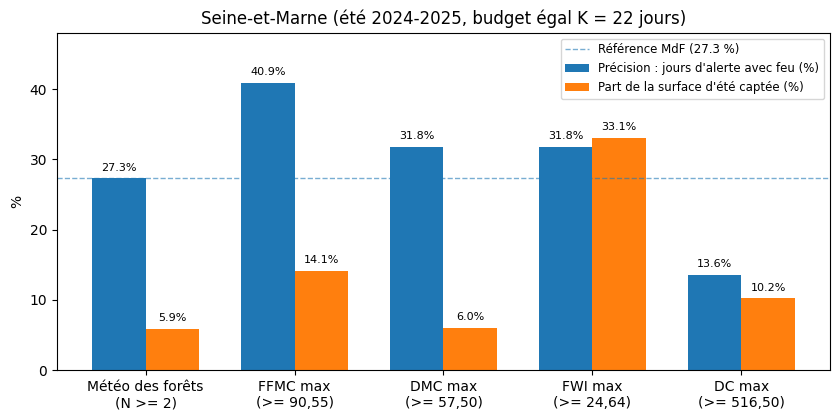

In [9]:
# Graphique comparatif : Météo des forêts vs les 4 indices Copernicus (règle max, K = 22 j)
sel = df_comp_mdf[df_comp_mdf['indicateur'].isin([
    'Météo des forêts (niveau >= 2)', 'ffmcode_max', 'dufmcode_max', 'fwinx_max', 'drtcode_max'
])].copy()

etiquettes = {
    'Météo des forêts (niveau >= 2)': 'Météo des forêts\n(N >= 2)',
    'ffmcode_max': 'FFMC max\n(>= 90,55)',
    'dufmcode_max': 'DMC max\n(>= 57,50)',
    'fwinx_max': 'FWI max\n(>= 24,64)',
    'drtcode_max': 'DC max\n(>= 516,50)',
}
sel['label'] = sel['indicateur'].map(etiquettes)

x = np.arange(len(sel))
w = 0.36
fig, ax = plt.subplots(figsize=(8.5, 4.3))
b1 = ax.bar(x - w/2, sel['precision_%'], width=w, label='Précision : jours d\'alerte avec feu (%)')
b2 = ax.bar(x + w/2, sel['surface_captee_%'], width=w, label='Part de la surface d\'été captée (%)')

ax.axhline(prec_mdf, linestyle='--', linewidth=1, alpha=0.6, label=f'Référence MdF ({prec_mdf:.1f} %)')
ax.set_xticks(x)
ax.set_xticklabels(sel['label'])
ax.set_ylabel('%')
ax.set_ylim(0, 48)
ax.set_title('Seine-et-Marne (été 2024-2025, budget égal K = 22 jours)')
ax.legend(loc='upper right', fontsize=8.5)

for bar in list(b1) + list(b2):
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 0.8, f'{h:.1f}%', ha='center', va='bottom', fontsize=8)

plt.tight_layout()

## 5. L'angle mort du printemps (`2024–2025`, `731` jours complets)

La *Météo des forêts* n'est publiée que de début juin à fin septembre (`04/06–01/10`). Copernicus couvre toute l'année : on mesure ce qui échappe à la fenêtre estivale, puis on teste le Top-`22` sur les `731` jours complets.

In [10]:
# Répartition avant le 03/06 vs fenêtre MdF vs après (2024 et 2025)
lignes_saisons = []
for an in [2024, 2025]:
    sub = b77[b77['Annee_int'] == an]
    avant_0306 = sub[sub['date_alerte'] < f'{an}-06-03']
    dans_mdf = sub[sub['date_concernee'].isin(set(mdf77['date_concernee']))]
    hors_mdf = sub[~sub['date_concernee'].isin(set(mdf77['date_concernee']))]
    lignes_saisons.append({
        'annee': an,
        'feux_total': len(sub),
        'surface_totale_m2': int(sub['surface_m2'].sum()),
        'feux_avant_03_06': len(avant_0306),
        'surface_avant_03_06_m2': int(avant_0306['surface_m2'].sum()),
        'part_surface_avant_03_06_%': round(100 * avant_0306['surface_m2'].sum() / sub['surface_m2'].sum(), 1),
        'feux_dans_fenetre_MdF': len(dans_mdf),
        'feux_hors_fenetre_MdF': len(hors_mdf),
        'surface_hors_fenetre_MdF_m2': int(hors_mdf['surface_m2'].sum()),
    })

display(pd.DataFrame(lignes_saisons))

# Top-22 sur l'année complète (731 j)
comp_731 = [evaluer_topk(table_731, col, k=22, ref_prec=prec_mdf) for col in ['ffmcode_max', 'dufmcode_max', 'fwinx_max', 'drtcode_max']]
print("Top-22 sur l'année complète (731 jours, 65 feux, 39 957 m2) :")
pd.DataFrame(comp_731)

,annee,feux_total,surface_totale_m2,feux_avant_03_06,surface_avant_03_06_m2,part_surface_avant_03_06_%,feux_dans_fenetre_MdF,feux_hors_fenetre_MdF,surface_hors_fenetre_MdF_m2
0,2024,10,2519,3,11,0.4,6,4,12
1,2025,55,37438,21,31097,83.1,30,25,31103


Top-22 sur l'année complète (731 jours, 65 feux, 39 957 m2) :


,indicateur,seuil_S,jours_alerte,jours_avec_feu,precision_%,ecart_pts_vs_MdF,feux_captes,surface_captee_%,surface_hors_alerte_%
0,ffmcode_max,90.76,22,8,36.4,9.1,12/65,3.1,96.9
1,dufmcode_max,60.75,22,8,36.4,9.1,12/65,1.3,98.7
2,fwinx_max,24.91,22,6,27.3,0.0,8/65,7.3,92.7
3,drtcode_max,516.50,22,3,13.6,-13.6,4/65,2.3,97.7


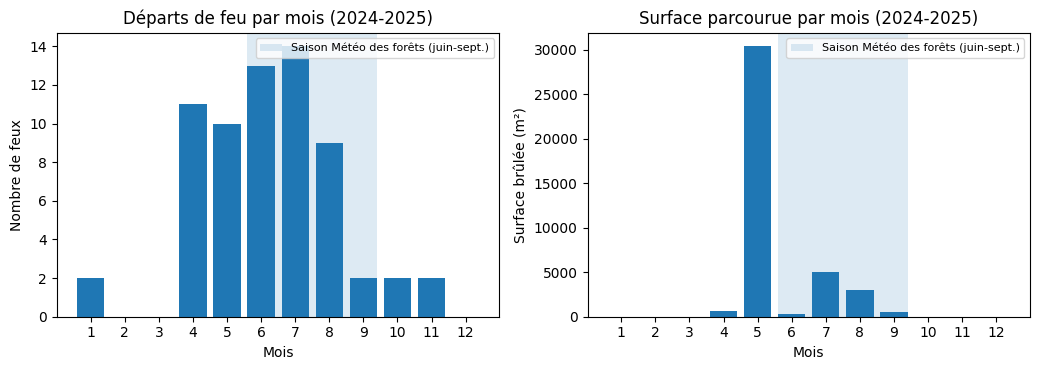

In [11]:
# Répartition mensuelle des feux et des surfaces brûlées dans le 77 (2024-2025)
b77['mois'] = b77['date_alerte'].dt.month
par_mois = (
    b77.groupby('mois')
    .agg(feux=('Numéro', 'count'), surface_m2=('surface_m2', 'sum'))
    .reindex(range(1, 13), fill_value=0)
)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8))
for ax, col, titre, ylab in [
    (axes[0], 'feux', 'Départs de feu par mois (2024-2025)', 'Nombre de feux'),
    (axes[1], 'surface_m2', 'Surface parcourue par mois (2024-2025)', 'Surface brûlée (m²)'),
]:
    ax.axvspan(5.6, 9.4, alpha=0.15, label='Saison Météo des forêts (juin-sept.)')
    ax.bar(par_mois.index, par_mois[col])
    ax.set_xticks(range(1, 13))
    ax.set_xlabel('Mois')
    ax.set_ylabel(ylab)
    ax.set_title(titre)
    ax.legend(fontsize=8)

plt.tight_layout()

## 6. Contrôle année par année (`2024` vs `2025`) et aperçu `2026`

Avant de conclure qu'un seuil Copernicus est supérieur à la Météo des forêts, il faut vérifier d'où vient le signal : une seule année sèche (`2025`) ou les deux années (`2024` et `2025`) ? On regarde aussi le contraste météorologique observé en `2026` (`01/01–31/08/2026`, sans BDIFF `2026` disponible).

In [12]:
lignes_annuelles = []
for an in [2024, 2025]:
    sub = table_731[table_731['annee'] == an]
    a_ffmc = sub[sub['ffmcode_max'] >= 90.55]
    a_fwi = sub[sub['fwinx_max'] >= 21.3]
    a_mdf = mdf77[(mdf77['annee_fichier'] == an) & (mdf77['niveau_j1'] >= 2)]
    lignes_annuelles.append({
        'annee': an,
        'jours_MdF_>=2': len(a_mdf),
        'jours_FFMC_max_>=90.55': len(a_ffmc),
        'jours_feu_si_FFMC_>=90.55': int(a_ffmc['jour_avec_feu'].sum()),
        'jours_FWI_max_>=21.3': len(a_fwi),
        'jours_feu_si_FWI_>=21.3': int(a_fwi['jour_avec_feu'].sum()),
        'surface_si_FWI_>=21.3_m2': int(a_fwi['surface_m2'].sum()),
        'surface_totale_m2': int(sub['surface_m2'].sum()),
    })

display(pd.DataFrame(lignes_annuelles))

# Aperçu 2026 (sans BDIFF 2026 publiée)
cop_26 = cop_77[cop_77['annee'] == 2026].groupby('date_concernee').agg(
    fwinx_max=('fwinx', 'max'),
    ffmcode_max=('ffmcode', 'max'),
)
mdf_26 = mdf77[mdf77['annee_fichier'] == 2026]
print(
    f"2026 (01/01 au 31/08, {len(cop_26)} j Copernicus) : "
    f"{int((cop_26['fwinx_max'] >= 21.3).sum())} j avec FWI_max >= 21.3 | "
    f"{int((cop_26['ffmcode_max'] >= 90.55).sum())} j avec FFMC_max >= 90.55 | "
    f"Météo des forêts 2026 ({len(mdf_26)} j) : {int((mdf_26['niveau_j1'] >= 2).sum())} j >= 2"
)

,annee,jours_MdF_>=2,jours_FFMC_max_>=90.55,jours_feu_si_FFMC_>=90.55,jours_FWI_max_>=21.3,jours_feu_si_FWI_>=21.3,surface_si_FWI_>=21.3_m2,surface_totale_m2
0,2024,0,2,0,2,0,0,2519
1,2025,22,23,9,37,13,33238,37438


2026 (01/01 au 31/08, 243 j Copernicus) : 79 j avec FWI_max >= 21.3 | 65 j avec FFMC_max >= 90.55 | Météo des forêts 2026 (131 j) : 89 j >= 2


## 7. Ce qu'on retient, limites et guide de reprise

### Synthèse des résultats
1. **Règle d'agrégation (`max`) :** sur `2024–2025`, la moyenne des 6 points du 77 masque les pics locaux au sud (Fontainebleau = `44,6 %` des feux) et fait rater le feu de `30 000 m²` du `16/05/2025` (`FWI_max = 22,20` vs `mean = 20,62`). Au seuil `FWI >= 21,3`, le `max` capte **`83,2 %`** de la surface brûlée contre `7,1 %` pour la `mean`.
2. **Gain sur la fenêtre d'été (`K = 22` jours sur `240` j) :** `FFMC_max >= 90,55` atteint **`40,9 %`** de jours d'alerte avec feu (`9 / 22`, soit **`+13,6` points** au-dessus de la Météo des forêts `6 / 22 = 27,3 %`), et `FWI_max >= 24,64` capte **`33,1 %`** de la surface d'été contre `5,9 %` pour la Météo des forêts.
3. **Angle mort du printemps :** en `2025`, **`83,1 %` de la surface brûlée (`31 097 / 37 438 m²`)** a brûlé **avant le `03/06`**, hors fenêtre Météo des forêts.

### Limites à garder en tête (repris dans la fiche G5)
- **Une seule saison sèche exploitable :** `2024` a été très humide (`0` jour MdF `>= 2`, seulement `2` jours `FFMC_max >= 90,55` sans feu). Tout le gain mesuré vient de `2025` : il reste exposé au surapprentissage tant qu'il n'est pas validé hors échantillon (par ex. sur `2026` dès la sortie de la BDIFF `2026`).
- **Réanalyse vs prévision :** Copernicus EWDS (`ERA5` / `GEFF`) mesure la météo réalisée a posteriori (midi solaire local), alors que `niveau_j1` est une prévision publiée la veille.
- **Autres biais :** maille large (`N320 ~0,28°`, `6` points seulement dans le 77), `77 %` des surfaces BDIFF estimées, feux hors forêt non comptabilisés (`décision 006`), mises à jour EWDS temporairement suspendues depuis le `16/11/2026`.

### Pour reprendre ce travail
- Les fichiers lus ici sont déjà versionnés dans `data/bronze/` sur `main`.
- Lorsque la BDIFF `2026` sera publiée, il suffira de l'ajouter dans `data/bronze/bdiff/` et de réexécuter la section 6 sur les données `2026` déjà présentes dans `data/bronze/copernicus/copernicus_2026_77.csv`.